# A ChIP-seq workflow

This guide puts the analysis functions of the package together into a single
motif analysis of real ChIP-seq peaks, from a BED file of peak coordinates
through to a ranked table of the motifs found in them. The other guides cover
the individual pieces in more depth, in particular
[scanning and enrichment](scanning-and-enrichment.ipynb),
[comparison and P-values](comparison-and-pvalues.ipynb) and
[choosing a background](background-models.ipynb), and this one assumes you
have at least skimmed the last of those.

The data are the ChIP-seq peaks of the *Arabidopsis thaliana* B3-domain
repressor VAL1 from Yuan et al. (2021). VAL1 and its paralogue VAL2 silence
seed maturation genes by binding the RY element, `CATGCA`, and recruiting
Polycomb Repressive Complex 2. If the analysis works as it should, then
given nothing but the peaks it ought to recover the RY element and match it
to a B3-domain transcription factor in JASPAR.

The workflow goes through the following steps:

1. Load the peaks from a BED file.
2. Extract fixed-width peak sequences from the genome.
3. Build a background of genomic windows matched to the peaks in GC content.
4. Discover motifs *de novo* with [`motif_finder()`][universalmotif.motif_finder].
5. Merge redundant discoveries with [`merge_similar()`][universalmotif.merge_similar].
6. Compare the motifs to the JASPAR plant collection with [`compare_motifs()`][universalmotif.compare_motifs].
7. Validate their enrichment with [`enrich_motifs()`][universalmotif.enrich_motifs].
8. Scan all of the peaks and test for central enrichment with [`motif_peaks()`][universalmotif.motif_peaks].
9. Look for motifs that occur together with [`motif_coocc()`][universalmotif.motif_coocc].

We close with a summary table that brings the evidence for each motif
together. Let us start with the imports:

In [1]:
import pathlib
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(40);

## Downloading the data

We need three files: the VAL1 peaks, the TAIR10 genome sequence from Ensembl
Plants, and the JASPAR 2024 collection of plant motifs in MEME format. This
small helper downloads each of them once into a cache directory in your home
folder, and reuses it on later runs (the genome is about 36 MB):

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / url.rsplit("/", 1)[-1]
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

bed_path = fetch("https://raw.githubusercontent.com/bjmt/universalmotif/master/inst/extdata/VAL1-GFP_val1_calledPeaks.bed")
genome_path = fetch("https://ftp.ensemblgenomes.ebi.ac.uk/pub/plants/current/fasta/arabidopsis_thaliana/dna/Arabidopsis_thaliana.TAIR10.dna.toplevel.fa.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_plants_non-redundant_pfms_meme.txt")

## Loading peaks from a BED file

A BED file is a plain tab-separated table without a header, whose first
three columns are the chromosome, the start and the end of each region, so
it can be read straight into a DataFrame. This one has six columns, and we
read the chromosome names as strings since they are the bare numbers `1` to
`5`:

In [3]:
peaks = pl.read_csv(
    bed_path, separator="\t", has_header=False,
    new_columns=["chrom", "start", "end", "name", "score", "strand"],
    schema_overrides={"chrom": pl.String},
)
peaks.head()

chrom,start,end,name,score,strand
str,i64,i64,str,i64,str
"""1""",21525,22017,""".""",86,"""."""
"""1""",48914,49492,""".""",86,"""."""
"""1""",104135,106515,""".""",1000,"""."""
"""1""",116059,116989,""".""",923,"""."""
"""1""",118241,119259,""".""",909,"""."""


Let us check how many peaks there are, how they are spread over the
chromosomes, and how wide they are:

In [4]:
print(peaks.height)
print(peaks["chrom"].value_counts(sort=True))
(peaks["end"] - peaks["start"]).describe()

5318
shape: (5, 2)
┌───────┬───────┐
│ chrom ┆ count │
│ ---   ┆ ---   │
│ str   ┆ u32   │
╞═══════╪═══════╡
│ 1     ┆ 1430  │
│ 5     ┆ 1145  │
│ 3     ┆ 1040  │
│ 2     ┆ 854   │
│ 4     ┆ 849   │
└───────┴───────┘


statistic,value
str,f64
"""count""",5318.0
"""null_count""",0.0
"""mean""",984.4088
"""std""",577.611758
"""min""",255.0
"""25%""",598.0
"""50%""",807.0
"""75%""",1190.0
"""max""",5337.0


There are 5318 peaks on the five nuclear chromosomes, with a median width of
807 bp and a few as wide as 5 kb.

## Extracting peak sequences

[`read_fasta()`][universalmotif.read_fasta] reads the gzipped genome
directly into a dict from names to sequences. Its headers carry a
description after the chromosome name, so we keep only the first word, which
gives names that match those in the BED file:

In [5]:
genome = {name.split()[0]: seq for name, seq in um.read_fasta(genome_path).items()}
{chrom: len(seq) for chrom, seq in genome.items()}

{'1': 30427671,
 '2': 19698289,
 '3': 23459830,
 '4': 18585056,
 '5': 26975502,
 'Mt': 366924,
 'Pt': 154478}

Rather than using the peaks as they are, we cut a fixed 500 bp window
centred on each of them. The fixed width matters later on, since
[`motif_peaks()`][universalmotif.motif_peaks] compares positions from one
sequence to the next, and if the sequences varied in length then the centre
would mean something different in each of them. BED starts are 0-based,
whereas the package counts from 1 and includes both ends, so we add one to
the starts first. Windows that would run off the end of a chromosome are
dropped, and each sequence is named after its coordinates:

In [6]:
mid = (peaks["start"] + 1 + peaks["end"]) // 2
windows = pl.DataFrame({"chrom": peaks["chrom"], "start": mid - 249, "end": mid + 250})
lengths = {chrom: len(seq) for chrom, seq in genome.items()}
windows = windows.filter(pl.col("start") >= 1, pl.col("end") <= pl.col("chrom").replace_strict(lengths))
peak_seqs = {f"{c}:{s}-{e}": genome[c][s - 1:e] for c, s, e in windows.iter_rows()}
print(len(peak_seqs))
next(iter(peak_seqs.values()))[:60]

5318


'GAATGGGATGGTAATAAAGAAAAAAATGACAGGAAACAATGAATTGGTCACGAAAAAATG'

None of the windows ran off a chromosome, so we keep all 5318 peaks. Note
that slicing a Python string makes a copy, so this approach suits a genome
of this size. For much larger genomes,
`read_fasta(path, packed=True)` holds the sequences in a quarter of the
memory, and the [large genomes](large-genomes.ipynb) guide shows how to work
with them.

## A composition-matched background

Plant promoters are strongly AT-rich, so any comparison between the peaks
and a background needs to control for composition, as the
[choosing a background](background-models.ipynb) guide shows. We build that
background once here and use it for both motif discovery and the enrichment
tests later on. Given the genome, [`match_bkg()`][universalmotif.match_bkg]
samples random windows of the same width as the peaks from the chromosomes
we name, avoiding the peaks themselves, and then picks one window for every
peak with a similar GC content:

In [7]:
bkg_seqs = um.match_bkg(
    peak_seqs, genome=genome, exclude=windows,
    chromosomes=["1", "2", "3", "4", "5"], seed=2026,
)
del genome
print(len(bkg_seqs))
list(bkg_seqs)[:3]

5318


['2:11767195-11767694', '4:13809826-13810325', '3:2985706-2986205']

The background windows are named after their coordinates too. We have no
further use for the genome after this, so we let it go to free its memory.
It is worth a quick check that the peaks and the background really do have
practically the same GC distribution:

In [8]:
def gc(seqs):
    return pl.Series([(s.count("G") + s.count("C")) / len(s) for s in seqs.values()])

pl.DataFrame({
    "statistic": gc(peak_seqs).describe()["statistic"],
    "peaks": gc(peak_seqs).describe()["value"],
    "background": gc(bkg_seqs).describe()["value"],
})

statistic,peaks,background
str,f64,f64
"""count""",5318.0,5318.0
"""null_count""",0.0,0.0
"""mean""",0.359847,0.359576
"""std""",0.057058,0.057662
"""min""",0.216,0.206
"""25%""",0.316,0.318
"""50%""",0.35,0.35
"""75%""",0.394,0.394
"""max""",0.586,0.592


Both sets have a median GC content of 35%, with the quartiles matching to
within 0.002.

## De novo motif discovery

[`motif_finder()`][universalmotif.motif_finder] searches for short k-mers
that are found in more of the target sequences than of the background ones,
builds motifs around them and refines them, and repeats this for every motif
width from `min_width` to `max_width`. Without a background it shuffles the
targets, but this tends to work less well for AT-rich plant sequences, since
a shuffle keeps each peak's own AT-richness and so can hide everything except
the strongest signals. We give it the matched background instead, and ask
for up to five motifs at each width:

In [9]:
found = um.motif_finder(
    peak_seqs, bkg_sequences=bkg_seqs, nmotifs=5,
    min_width=6, max_width=12, seed=2026, nthreads=2,
)
found.select("name", "consensus", "seqs_pos", "seqs_neg", "pvalue")

name,consensus,seqs_pos,seqs_neg,pvalue
str,str,i64,i64,f64
"""motif_1""","""SCATGCA""",1925,374,6.0145e-314
"""motif_2""","""CATGCATG""",1693,413,2.2045e-225
"""motif_3""","""ACATGCA""",1591,518,6.4619e-156
"""motif_4""","""CCATGCAAA""",1789,677,3.8221e-148
"""motif_5""","""TCATGCA""",1029,351,1.6361e-88
"""motif_6""","""CACGTG""",1020,385,2.8355e-76
"""motif_7""","""GTACGTR""",780,245,2.6141e-72
"""motif_8""","""AACACATGCAA""",1501,785,4.7349e-65
"""motif_9""","""ACGTACGTA""",569,192,1.4841e-47


This takes a few seconds, and it returns 15 motifs in order of P-value along
with the motifs themselves in the `motif` column. The `seqs_pos` and
`seqs_neg` columns count the peaks and background windows with a hit. The
RY element dominates the top of the list, with `SCATGCA` found in 1925
peaks against 374 background windows, and the next few motifs are mostly
variations of it. Further down are a G-box, `CACGTG`, an `ACGTACGTA`
palindrome, a GC-rich `CCGSCG`, and several low-complexity repeats of A, GA
and TA. (The smallest P-values here are close to the smallest number that
can be represented, so they are best read simply as "extremely small".)

## Removing redundant discoveries

A discovery run almost always returns several shifted or extended copies of
the same signal, as it has here with the RY element. These variations can
sometimes be biologically meaningful, but for simplicity we will not dwell
on them. [`merge_similar()`][universalmotif.merge_similar] compares all of
the motifs with [`compare_motifs()`][universalmotif.compare_motifs], links
the pairs with a q-value of at most `qvalue`, and merges each linked cluster
into one motif. Let us first look at the clusters it finds:

In [10]:
discovered = found["motif"].to_list()
clusters = um.merge_similar(discovered, qvalue=0.01, return_clusters=True)
clusters.select("name", "consensus", "cluster")

name,consensus,cluster
str,str,i64
"""motif_1""","""SCATGCA""",0
"""motif_2""","""CATGCATG""",0
"""motif_3""","""ACATGCA""",0
"""motif_4""","""CCATGCAAA""",0
"""motif_5""","""TCATGCA""",0
"""motif_6""","""CACGTG""",1
"""motif_7""","""GTACGTR""",2
"""motif_8""","""AACACATGCAA""",0
"""motif_9""","""ACGTACGTA""",2


The six RY variants form one cluster, the two `ACGTAC`-like motifs another,
and the two `CCGACCC`-like ones a third, leaving eight clusters in all. Now
let us merge them, and trim the merged motifs with
[`trim_motifs()`][universalmotif.trim_motifs] in case merging has added
uninformative positions to their edges:

In [11]:
merged = um.trim_motifs(um.merge_similar(discovered, qvalue=0.01))
[m.name for m in merged]

['merged_motif_1+motif_2+motif_3+motif_4+motif_5+motif_8',
 'motif_6',
 'merged_motif_7+motif_9',
 'motif_10',
 'motif_11',
 'motif_12',
 'motif_13',
 'merged_motif_14+motif_15']

The merged motifs are named by joining the names of the motifs that went
into them, which quickly becomes unwieldy. So let us give each of them a
label based on its consensus, falling back to the consensus itself for
motifs we do not have a name for, so that the rest of the guide can refer to
the motifs by what they are:

In [12]:
labels = [
    ("CATGCA|TGCATG", "RY"),
    ("CACGTG", "G_box"),
    ("ACGTAC|GTACGT", "ACGTAC"),
    ("GAGAGA|TCTCTC", "GA_repeat"),
    ("TATATA|ATATAT", "TA_repeat"),
    ("AAAAAA|TTTTTT", "A_run"),
]

def label(motif):
    for pattern, name in labels:
        if pl.Series([motif.consensus]).str.contains(pattern)[0]:
            return name
    return motif.consensus

merged = [m.replace(name=label(m)) for m in merged]
um.summarise_motifs(merged).select("name", "consensus", "icscore", "nsites")

name,consensus,icscore,nsites
str,str,f64,f64
"""RY""","""AACNCATGCAWR""",13.093583,12491.0
"""G_box""","""CACGTG""",10.245237,1828.0
"""ACGTAC""","""ACGTACGTA""",13.806873,1909.0
"""CCGSCG""","""CCGSCG""",10.969468,1358.0
"""GA_repeat""","""GAGAGAGAGAGA""",13.418508,7322.0
"""A_run""","""AAAAAAAAAAA""",16.293567,9459.0
"""TA_repeat""","""TATATATATATA""",17.721352,3622.0
"""CCRACCCGACCCG""","""CCRACCCGACCCG""",11.516878,2128.0


[`view_motifs()`][universalmotif.view_motifs] draws them as logos. With
`sort_by="similarity"` the motifs are ordered by clustering, so that related
logos end up next to each other, and motifs that line up better as reverse
complements are flipped and marked with [RC]:

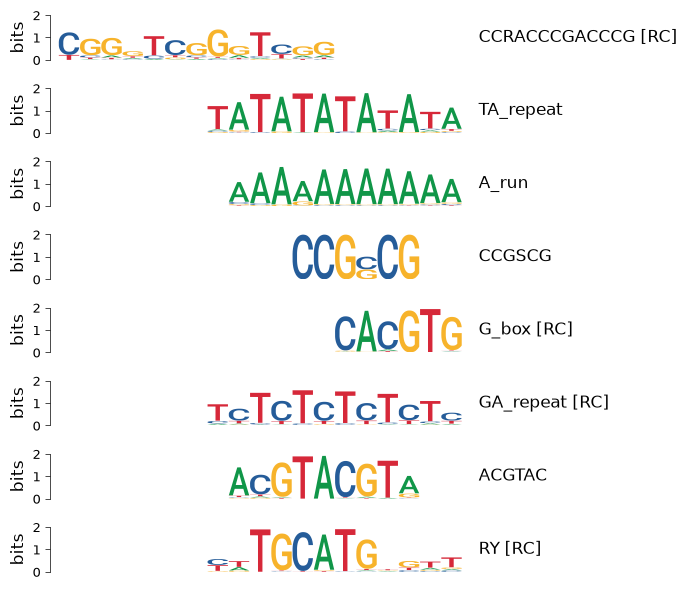

In [13]:
fig = um.view_motifs(merged, sort_by="similarity", names_pos="right", show_positions=False, figsize=(7, 6))

## Comparing with JASPAR

Next, let us see which known motifs our discoveries resemble. We read the
JASPAR plant collection with [`read_meme()`][universalmotif.read_meme], in
which each motif's name is its JASPAR ID and its alternative name is the
transcription factor. [`compare_motifs()`][universalmotif.compare_motifs]
compares the motifs we give it as `compare_to` with every motif in the list,
so we put our eight motifs first and pass their indices. Since that includes
comparing them with one another, we keep only the rows for JASPAR motifs,
and sort the matches of each motif by q-value and then by score:

In [14]:
jaspar = um.read_meme(jaspar_path)
tf_names = {m.name: m.altname for m in jaspar}
print(len(jaspar))
cmp = um.compare_motifs(merged + jaspar, compare_to=list(range(len(merged))), qvalue=0.2, nthreads=2)
cmp = (
    cmp.filter(pl.col("target_i") >= len(merged))
    .with_columns(tf=pl.col("target").replace_strict(tf_names))
    .sort("qvalue", pl.col("score"), descending=[False, True])
)
cmp.group_by("subject", maintain_order=True).head(3).select(
    "subject", "target", "tf", "score", "target_consensus", "qvalue"
)

805


subject,target,tf,score,target_consensus,qvalue
str,str,str,f64,str,f64
"""GA_repeat""","""MA1404.1""","""BPC1""",0.995257,"""GAGAGAGAGAGA""",0.000019
"""GA_repeat""","""MA1402.1""","""BPC6""",0.992036,"""TCTCTCTCTCTC""",0.000019
"""GA_repeat""","""MA1416.1""","""RAMOSA1""",0.991633,"""GAGAGAGAGAGA""",0.000046
"""A_run""","""MA1274.1""","""DOF3.6""",0.958263,"""TTTTYHHYYYY""",0.000531
"""A_run""","""MA1267.2""","""DOF5.8""",0.941754,"""YYYYHHYYWWY""",0.000544
"""A_run""","""MA1268.2""","""CDF5""",0.923501,"""TTTTYHYYWWY""",0.000695
"""G_box""","""MA1360.3""","""bHLH74""",0.999742,"""CACGTG""",0.008617
"""G_box""","""MA0964.3""","""BIM1""",0.999742,"""CACGTG""",0.008617
"""G_box""","""MA0965.3""","""BIM2""",0.999737,"""CACGTG""",0.008617


This shows the top three matches of each motif with a q-value of at most
0.2. Counting all of the matches is informative too:

In [15]:
cmp.group_by("subject").len().sort("len", descending=True)

subject,len
str,u32
"""G_box""",102
"""CCGSCG""",86
"""A_run""",22
"""GA_repeat""",4
"""ACGTAC""",4
"""RY""",1


The G-box matches 102 JASPAR motifs, which is no surprise since `CACGTG` is
bound by a great many bHLH and bZIP factors, and the GC-rich `CCGSCG`
matches 86. The GA repeat matches the BPC family,
which binds GAGA repeats, and the A run matches several DOF motifs, which
in this collection are T-rich and so line up with the A run on the opposite
strand. Note that some JASPAR plant motifs are
named after maize gene identifiers, which is why the best matches of
`ACGTAC` look the way they do. `TA_repeat` and `CCRACCCGACCCG` have no
matches at all.

The RY element, on the other hand, has just one match, FUS3, with a q-value
of 0.086. That may look modest, but FUS3 is itself a B3-domain transcription
factor that binds the RY element, which makes it a biologically sensible
neighbour for VAL1. Let us draw the two together:

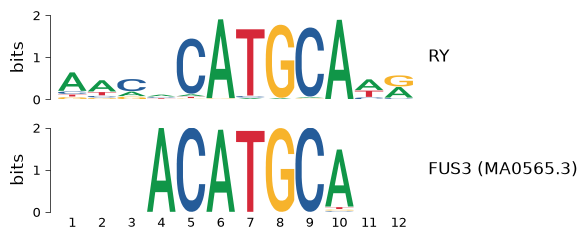

In [16]:
ry = next(m for m in merged if m.name == "RY")
best = cmp.filter(pl.col("subject") == "RY").row(0, named=True)
ry_ref = next(m for m in jaspar if m.name == best["target"])
ry_ref = ry_ref.replace(name=f"{ry_ref.altname} ({ry_ref.name})")
fig = um.view_motifs([ry, ry_ref], names_pos="right", figsize=(6, 2.5))

The cores line up exactly, and the discovered motif carries a few weakly
informative positions on either side.

## Validating enrichment

The discovery P-values come from the same sequences the motifs were found
in, so they are not an independent test. Let us test the merged motifs with
[`enrich_motifs()`][universalmotif.enrich_motifs], which scans the peaks and
the matched background and runs a Fisher's exact test on the number of
sequences with a hit.

First, however, it is worth checking that each motif can actually reach the
P-value cutoff we choose. A short motif can only score so highly, and if
even its best possible match is more likely than the cutoff then it gets no
hits at all. Let us compute the P-value of each motif's highest score with
[`motif_score()`][universalmotif.motif_score] and
[`motif_pvalue()`][universalmotif.motif_pvalue]:

In [17]:
best_p = um.motif_pvalue(merged, score=[um.motif_score(m, 1.0) for m in merged])
pl.DataFrame({"motif": [m.name for m in merged], "best_pvalue": best_p})

motif,best_pvalue
str,f64
"""RY""",3.6294e-8
"""G_box""",0.000107
"""ACGTAC""",0.000004
"""CCGSCG""",0.000034
"""GA_repeat""",3.6357e-8
"""A_run""",0.000004
"""TA_repeat""",0.000001
"""CCRACCCGACCCG""",6.5055e-10


A perfect match to the six-letter G-box has a P-value of 1.07e-4, so with the
usual cutoff of 1e-4 it would never get a single hit. We use a cutoff of
2e-4 instead, which lets in perfect G-box matches and is still strict for the
longer motifs:

In [18]:
enr = um.enrich_motifs(merged, peak_seqs, bkg_sequences=bkg_seqs, pvalue=2e-4, qvalue=1, nthreads=2)
enr.select("motif", "target_seq_hits", "bkg_seq_hits", pl.col("enrichment").round(2), "qvalue")

motif,target_seq_hits,bkg_seq_hits,enrichment,qvalue
str,i64,i64,f64,f64
"""RY""",2849,1142,2.49,2.1744e-261
"""G_box""",851,277,3.07,2.1037e-75
"""ACGTAC""",977,358,2.73,2.4828e-75
"""CCGSCG""",1078,617,1.75,1.8002e-34
"""A_run""",2917,2412,1.21,1.1040e-22
"""GA_repeat""",2711,2259,1.2,1.2061e-18
"""TA_repeat""",1094,787,1.39,3.9170e-15
"""CCRACCCGACCCG""",1346,1070,1.26,9.6242e-11


Every motif is significantly enriched, which is to be expected since they
were discovered against this very background, but the enrichment ratios
separate them clearly. The G-box, `ACGTAC` and the RY element are found in
2.5 to 3 times as many peaks as background windows, whereas the
low-complexity repeats sit at 1.2 to 1.4. To see why the matched background
matters, let us run the same test against a dinucleotide shuffle of the
peaks:

In [19]:
enr_shuffled = um.enrich_motifs(merged, peak_seqs, pvalue=2e-4, qvalue=1, shuffle_k=2, seed=2026, nthreads=2)
enr_shuffled.select("motif", "target_seq_hits", "bkg_seq_hits", pl.col("enrichment").round(2), "qvalue")

motif,target_seq_hits,bkg_seq_hits,enrichment,qvalue
str,i64,i64,f64,f64
"""RY""",2849,1044,2.73,2.1555e-296
"""A_run""",2917,1306,2.23,2.2944e-227
"""GA_repeat""",2711,1145,2.37,3.0756e-223
"""TA_repeat""",1094,264,4.14,4.1552e-136
"""G_box""",851,262,3.25,6.0543e-81
"""ACGTAC""",977,455,2.15,1.2260e-50
"""CCGSCG""",1078,657,1.64,1.0889e-28
"""CCRACCCGACCCG""",1346,1045,1.29,1.5517e-12


Against the shuffle, the A run, GA repeat and TA repeat jump to 2.2- to
4.1-fold enrichment, with the TA repeat now looking more enriched than the
RY element. Shuffling breaks up repeats that are common across the whole
genome, so against a shuffled background they look far more special than
they are. The genomic background tells us that they are only slightly more
common in the peaks than elsewhere.

## Scanning and positional bias

To see where in the peaks the motifs fall, we scan all of the peaks with
[`scan_sequences()`][universalmotif.scan_sequences], using the same cutoff:

In [20]:
hits = um.scan_sequences(merged, peak_seqs, pvalue=2e-4, nthreads=2)
print(hits.height)
hits.group_by("motif").agg(hits=pl.len(), sequences=pl.col("sequence_i").n_unique()).sort("hits", descending=True)

43968


motif,hits,sequences
str,u32,u32
"""A_run""",14851,2917
"""GA_repeat""",10876,2711
"""TA_repeat""",5691,1094
"""RY""",4602,2849
"""CCRACCCGACCCG""",2237,1346
"""G_box""",2040,851
"""CCGSCG""",1882,1078
"""ACGTAC""",1789,977


The repeats have the most hits, since a long repeat matches at many
overlapping positions, but the RY element is found in almost as many peaks
as the A run. [`motif_peaks()`][universalmotif.motif_peaks] then asks, for
each motif, whether its hits gather around the centre of the peaks. Taking
the best hit of each motif in every sequence, it counts how many fall inside
windows of increasing width around the centre, and compares that with the
number expected if the hits were spread evenly along the sequences:

In [21]:
pk = um.motif_peaks(hits, seq_length=500, qvalue=1, nthreads=2)
pk.select("motif", "nhits", "best_window", "hits_in", pl.col("expected_in").round(1), pl.col("enrichment").round(2), "qvalue")

motif,nhits,best_window,hits_in,expected_in,enrichment,qvalue
str,i64,i64,i64,f64,f64,f64
"""RY""",2849,170,1376,968.7,1.42,1.7504e-53
"""ACGTAC""",977,250,569,488.5,1.16,0.000014
"""GA_repeat""",2711,100,595,542.2,1.1,0.429539
"""TA_repeat""",1094,230,539,503.2,1.07,0.815691
"""G_box""",851,200,370,340.4,1.09,0.84798
"""A_run""",2917,10,59,58.3,1.01,1.0
"""CCGSCG""",1078,60,135,129.4,1.04,1.0
"""CCRACCCGACCCG""",1346,250,699,673.0,1.04,1.0


A motif that drives binding ought to gather at the centre, and the RY
element does so very clearly, with 1376 of its 2849 best hits in the central
170 bp against 968.7 expected. `ACGTAC` is also centrally enriched, though
much more weakly and over a broad window of 250 bp. None of the other motifs
passes a q-value of 0.1, the G-box included, even though it was the most
enriched motif in the peaks. Let us plot four of them with
[`plot_motif_peaks()`][universalmotif.plot_motif_peaks], which shades the
best window of each:

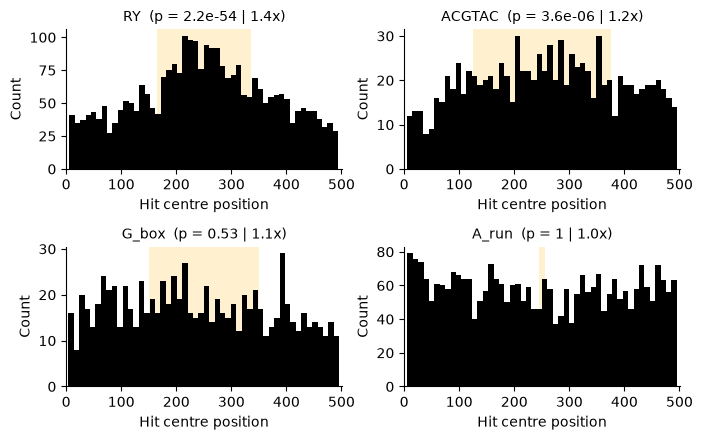

In [22]:
fig = um.plot_motif_peaks(pk, motifs=["RY", "ACGTAC", "G_box", "A_run"], figsize=(7, 4.5))

The RY element has a clear hump at the centre and `ACGTAC` a much flatter
one, whereas the hits of the G-box are only slightly more common towards the
centre and those of the A run are spread evenly. A motif
that is enriched in the peaks without favouring their centre may still be
biologically relevant, since peaks often lie in promoters, where many motifs
are common. But it is less likely to be bound directly by the factor that
was immunoprecipitated.

## Co-occurrence

[`motif_coocc()`][universalmotif.motif_coocc] asks whether pairs of motifs
share peaks more often than expected from how common each of them is. With
`max_distance` it also counts, for each pair, the shared peaks in which the
two motifs' nearest hits are within that distance of each other, along with
the median of those nearest distances. B3-domain factors are known to bind
tandem RY elements, so we also pair each motif with itself using
`self_pairs`. Let us look at the self pairs first:

In [23]:
co = um.motif_coocc(merged, hits=hits, n_sequences=len(peak_seqs), max_distance=50, self_pairs=True, nthreads=2)
co.filter(pl.col("motif_a") == pl.col("motif_b")).select("motif_a", "both", "both_clustered", "median_distance")

motif_a,both,both_clustered,median_distance
str,i64,i64,f64
"""RY""",2849,803,4.0
"""G_box""",851,851,0.0
"""ACGTAC""",977,511,1.0
"""CCGSCG""",1078,365,2.0
"""GA_repeat""",2711,1865,2.0
"""A_run""",2917,2251,1.0
"""TA_repeat""",1094,857,0.0
"""CCRACCCGACCCG""",1346,363,5.0


For a motif paired with itself the test is meaningless, since every peak with
a hit trivially has "both", so only the distance columns are of interest
here. Of the 2849 peaks with an RY hit, 803 have two of them within 50 bp,
with a median distance of just 4 bp. The G-box has a median distance of 0
for a less interesting reason, which is that `CACGTG` is its own reverse
complement, so every site is found once on each strand at the same position.
To get a better picture of the RY element, let us collect the distances
between every pair of RY hits in the same peak and plot them:

2690 [ 87   0   0   0 828   4  11   8  74   8   8  10  15]


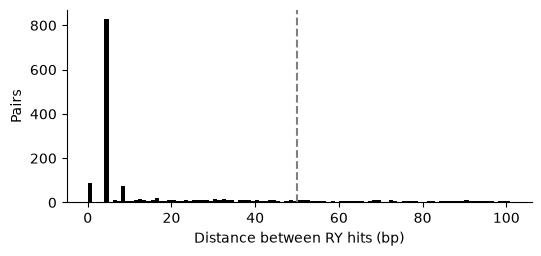

In [24]:
ry_hits = hits.filter(pl.col("motif") == "RY")
distances = []
for (_,), group in ry_hits.group_by("sequence_i"):
    starts = np.sort(group["start"].to_numpy())
    distances.extend(np.abs(starts[:, None] - starts[None, :])[np.triu_indices(len(starts), 1)])
distances = np.array(distances)
print(len(distances), np.bincount(distances[distances <= 12]))

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.hist(distances[distances <= 100], bins=np.arange(0, 102), color="black")
ax.axvline(50, ls="--", color="grey")
ax.set(xlabel="Distance between RY hits (bp)", ylabel="Pairs")
ax.spines[["top", "right"]].set_visible(False)

Of the 2690 pairs, 828 are exactly 4 bp apart, with much smaller peaks at 0
and 8 bp. What sits at those 4 bp? Let us take every pair of neighbouring
RY hits 4 bp apart, and look at the eight letters starting from the core of
the first hit:

In [25]:
names = list(peak_seqs)
pairs = ry_hits.sort("sequence_i", "start").with_columns(
    next_start=pl.col("start").shift(-1).over("sequence_i")
).filter(pl.col("next_start") - pl.col("start") == 4)
cores = pl.Series("core", [peak_seqs[names[i]][s + 3:s + 11] for i, s in pairs.select("sequence_i", "start").iter_rows()])
cores.value_counts(sort=True).head(5)

core,count
str,u32
"""CATGCATG""",548
"""TATGCATG""",30
"""CATGCATA""",30
"""AATGCATG""",16
"""CATGCATT""",16


By far the most common is `CATGCATG`, two RY elements reading in opposite
directions and sharing four letters, which is the repeated form of the RY
element found in the promoters of seed genes. The scan reports it as two
overlapping hits, one on each strand and 4 bp apart. That this arrangement turns up
in so many peaks is a nice confirmation that the peaks really are RY-bound.

Now for the pairs of different motifs, sorted by q-value:

In [26]:
cross = co.filter(pl.col("motif_a") != pl.col("motif_b"))
cross.head(8).select("motif_a", "motif_b", "both", pl.col("odds_ratio").round(2), "qvalue", "both_clustered", "median_distance")

motif_a,motif_b,both,odds_ratio,qvalue,both_clustered,median_distance
str,str,i64,f64,f64,i64,f64
"""CCGSCG""","""CCRACCCGACCCG""",434,2.46,9.6415e-34,194,14.0
"""RY""","""TA_repeat""",678,1.54,7.4768e-10,216,22.0
"""GA_repeat""","""A_run""",1586,1.35,9.2081e-8,846,2.0
"""ACGTAC""","""TA_repeat""",261,1.54,5.3449e-7,93,21.0
"""CCGSCG""","""GA_repeat""",619,1.38,0.000003,194,22.0
"""RY""","""A_run""",1630,1.23,0.000288,502,27.0
"""G_box""","""CCGSCG""",213,1.39,0.000315,59,24.0
"""G_box""","""CCRACCCGACCCG""",255,1.32,0.001014,82,27.0


The strongest pair is the two GC-rich motifs `CCGSCG` and `CCRACCCGACCCG`,
which share 434 peaks with an odds ratio of 2.46, likely because both are
found in the same GC-rich stretches. The RY element's strongest partner is
the TA repeat, with an odds ratio of 1.54 but a median distance of 22 bp
between them, which says little about any direct relationship. And what of
the RY element and the G-box, which are known to occur together in seed
maturation promoters?

In [27]:
cross.filter(pl.col("motif_a").is_in(["RY", "G_box"]), pl.col("motif_b").is_in(["RY", "G_box"])).select(
    "motif_a", "motif_b", "both", pl.col("odds_ratio").round(2), "qvalue"
)

motif_a,motif_b,both,odds_ratio,qvalue
str,str,i64,f64,f64
"""RY""","""G_box""",421,0.82,1.0


They share slightly fewer peaks than expected by chance, with an odds ratio
of 0.82, though not significantly so. So whatever the role of the G-box here,
these peaks give no sign of it working alongside the RY element.

## Summary

Finally, let us pull everything together into one table, with a row for
each motif giving its best JASPAR match, its enrichment against the matched
background and q-value, the q-value of its central enrichment, and its best
partner among the other motifs:

In [28]:
def first(df, motif_col, motif, value):
    rows = df.filter(pl.col(motif_col) == motif)
    return rows[value][0] if rows.height else None

def best_partner(motif):
    rows = cross.filter((pl.col("motif_a") == motif) | (pl.col("motif_b") == motif))
    if not rows.height:
        return None
    a, b = rows.row(0)[:2]
    return b if a == motif else a

summary = pl.DataFrame({
    "motif": [m.name for m in merged],
    "jaspar_match": [first(cmp, "subject", m.name, "tf") for m in merged],
    "enrichment": [first(enr, "motif", m.name, "enrichment") for m in merged],
    "enrich_q": [first(enr, "motif", m.name, "qvalue") for m in merged],
    "central_q": [first(pk, "motif", m.name, "qvalue") for m in merged],
    "best_partner": [best_partner(m.name) for m in merged],
}).with_columns(pl.col("enrichment").round(2))
summary

motif,jaspar_match,enrichment,enrich_q,central_q,best_partner
str,str,f64,f64,f64,str
"""RY""","""FUS3""",2.49,2.1744e-261,1.7504e-53,"""TA_repeat"""
"""G_box""","""bHLH74""",3.07,2.1037e-75,0.84798,"""CCGSCG"""
"""ACGTAC""","""Zm00001d018571""",2.73,2.4828e-75,0.000014,"""TA_repeat"""
"""CCGSCG""","""AS2""",1.75,1.8002e-34,1.0,"""CCRACCCGACCCG"""
"""GA_repeat""","""BPC1""",1.2,1.2061e-18,0.429539,"""A_run"""
"""A_run""","""DOF3.6""",1.21,1.1040e-22,1.0,"""GA_repeat"""
"""TA_repeat""",null,1.39,3.9170e-15,0.815691,"""RY"""
"""CCRACCCGACCCG""",null,1.26,9.6242e-11,1.0,"""CCGSCG"""


Taking the evidence together, the analysis has clearly recovered the RY
element as the motif behind VAL1 binding. It is strongly enriched against
the matched background, it matches the B3-domain factor FUS3, it gathers at
the centre of the peaks, and it is often found in its repeated `CATGCATG`
form. `ACGTAC` is the only other motif that is both enriched and central,
and it may well be the site of a factor working alongside VAL1, though its
JASPAR matches are too weak to say which. The G-box is enriched but shows no
preference for the centre of the peaks, and the low-complexity repeats are
only slightly enriched and are likely just features of the kinds of regions
VAL1 tends to bind. Of course, none of this proves that VAL1 binds the RY
element directly in these peaks, but it is about as clear a result as a
motif analysis of ChIP-seq peaks can give.

From here, the [API reference](../reference/index.md) describes every
function used in this guide, along with others not covered here such as
[`motif_proximity()`][universalmotif.motif_proximity] for testing whether
motif hits gather near genomic features like transcription start sites.